# Baseline8: Dinomaly, a fresh max 100-epoch Kaggle run

This notebook preserves the official pinned Dinomaly-B model, frozen official DINOv2
register4 encoder, noisy bottleneck, eight Transformer decoder blocks, native losses,
actual batch 16, and native feature anomaly maps. It changes the **training budget and
normal-only selection policy** for the newly standardized comparison.

**What changes:** maximum 100 epochs, normal selection every completed epoch, patience 10.
The stopping anchor needs more than0.1% improvement (absolute floor1e-8); the evaluated
checkpoint separately retains the lowest observed normal loss. Native Dinomaly used
5,000 updates and the final checkpoint. The cosine schedule is therefore built fresh over
23,900 updates, with the same 100-step warmup and LR0.002→0.0002 endpoints. The source hard
mining ramp remains1,000 updates. These are explicit benchmark adaptations.

**Start fresh:** leave `RESUME_DIR=''` for this new run. Your old5000-step result stays intact;
its `last.pt` cannot be imported because its LR trajectory is different. Resume only this
notebook's own max100 run by attaching its output and setting `RESUME_DIR` to the folder
containing `config.json` and `last.pt`. `last.pt` includes the best-head snapshot, RNG,
optimizer, schedule, epoch counters and partial epoch sums. `best.pt` is written once the
scientific run finishes. Session pausing does not complete a run or evaluate test labels.

**Inputs:** the same `ws2-eca` data as earlier notebooks, with the unchanged
3,829 train/521 select/128 calibrate/234 audit/496 test split. Enable Kaggle GPU and Internet.
Author code and the SHA-verified official DINOv2 weights download automatically; optional
source and weight overrides are available. No Christian/QMEM/repair checkpoint is needed.

**Epoch meaning:** a seeded permutation of3829 training frames, actual batch 16 and native
`drop_last=True`:239 updates and3,824 frames per epoch. Thirteen frames are omitted from each
shuffled epoch; the omitted identities change between epochs. Equal epoch caps do not make
pretraining, total parameters, image exposure, or compute equal. This is a broader
**pretrained feature-reconstruction baseline**, not a capacity-matched RGB autoencoder.
It has148008960 total parameters:61425408 trainable and86583552 frozen.

**Runtime:** the old5000-step run took approximately 4.5 hours. A full100-epoch cap can exceed
20 hours and need multiple sessions; early stopping may finish earlier. The notebook pauses
near 9 hours with a 5-minute save buffer and atomically commits every 100updates or epoch boundary.
No smoke switch, test-label selection, or silent shortening of the scientific budget is used.

**Output to send:** `Dinomaly100_baseline_8_report.zip` and executed notebook/log. Keep
`last.pt`, `config.json`, `best.pt` when produced, and `Dinomaly100_baseline_8_resume.zip`.
No large `.npy` files are needed initially. Headline rows include mean foreground frame IoU,
Dice, precision, recall, pixel AP/AUROC/AUPRO, audited FPR, epoch/step counts and parameters.
Historical and independent-calibration rows are labelled separately. Image AUROC/AP stay
undefined when the test set lacks both image classes.

Sources: [official code at the locked commit](https://github.com/guojiajeremy/Dinomaly/tree/1f252be03a918789b19848f0ca37166e7c28dada),
[CVPR2025 paper](https://openaccess.thecvf.com/content/CVPR2025/html/Guo_Dinomaly_The_Less_Is_More_Philosophy_in_Multi-Class_Unsupervised_Anomaly_CVPR_2025_paper.html).


## 1. Configuration

New output paths preserve the legacy5000-step result. Path overrides are optional. The fixed max100 rule is separate from the9hour session guard.

In [1]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
import math, ast, warnings, importlib, importlib.util, importlib.metadata
import subprocess, urllib.request
from pathlib import Path
from functools import partial

# Full run. Attach the same ws2-eca dataset. Enable a Kaggle GPU and Internet.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/Dinomaly_baseline_8_max100')
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
RESUME_DIR = '/kaggle/input/models/neolore/dino-v3/pytorch/default/1'  # Previous output folder containing config.json and last.pt.
SOURCE_DIR_OVERRIDE = ''  # Optional: directory containing the pinned source files.
BACKBONE_WEIGHTS_OVERRIDE = ''  # Optional: official dinov2_vitb14_reg4_pretrain.pth.

SEED = 1337
SIZE = 256             # Identical evaluated frame and mask grid to prior baselines.
MODEL_SIZE = 392       # Official 28 x 28 patch grid. Full-frame resize, NO center crop.
MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
EARLY_STOPPING_MIN_DELTA = 1e-8
EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT = 0.001
# TOTAL_STEPS is set from the exact split after membership verification.
BATCH = 16            # Actual batch, NOT microbatches: hard mining is batch-wide.
EVAL_BATCH = 4
WORKERS = 2
LR = 2e-3
SAVE_EVERY = 100
SESSION_HOURS = 20.0
SESSION_SAVE_BUFFER_SECONDS = 300
SESSION_START = time.monotonic()
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('dinomaly_feature_cosine',)
MODEL_LABEL = 'Dinomaly_B_reg4_WS2_fullframe_392_max100_normalbest'
DINOMALY_COMMIT = '1f252be03a918789b19848f0ca37166e7c28dada'
SOURCE_HASHES = {'LICENSE': 'a4a9fdc7cdc83557c03da97c2157ab1f186469b0b0e94e54201e9e895a8c8d3c', 'README.md': 'd40e030e5539fdea6f12b1d0377b70ede72b89ab3d646b69a7fb127aee892fa3', 'requirements.txt': '601f03c90aec8bc35b1016dc014ac96847ea8c04fef660cb819cef1b8d4698d3', 'dinomaly_mvtec_sep.py': '4069147688db014ac3376d26e8e17fad4317c1d2d09fc4898d05c063bb402ade', 'dataset.py': '6f41abc3233d287786430b3377aa8ae7c03c12c20583da186606042d44feaa45', 'utils.py': '5691ee260b1bbad230058d0945ab19e46b215da5cae0186b1090c359a8231b3a', 'models/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'models/uad.py': 'ac16991c34b5005ba7a259c99e13e2610bb82fb4196ac9082cecf88e0c5b4239', 'models/vision_transformer.py': 'f972c48485e930438ae38962c0fa6289170dfd6088b8b9e5704f33544ca6cd13', 'models/vit_encoder.py': 'aace0c592c3af659952e1f51145cf48bf9d67732b6d4b78fa210bd1f9b5bf8de', 'dinov1/utils.py': '123ef09449090c72f352471937fefaa0b0d678fdc29bf07eb6c7626593eeab09', 'dinov2/__init__.py': '0d2b87b7e71c7f7279ccc4b4f8b541d26071425284a0ea01a5a435fac4511cfe', 'dinov2/models/__init__.py': '87b360c71997314f41be1c497cc42326fc32617d3a2840f2f19d3795ca8b85ee', 'dinov2/models/vision_transformer.py': '0abdd2762129a2d324371250918acfb023b7edba7458c8e8969c5f8ba58752b0', 'optimizers/StableAdamW.py': 'd06d25a7c1aa9717fb73283783fd862b73e613a4eaae67c0427fe3e2115aed6e', 'dinov2/layers/__init__.py': 'a23f101c4eb31288c20a4dda4bfe64dff23dc73e94dcac42eb3dee7e335ccd2b', 'dinov2/layers/attention.py': 'e25158047e0ff6b22ba4c029b37d370f9b40b764edab21a7608045dd7a1c5424', 'dinov2/layers/block.py': 'b3dc871d046ed8f11a68f7a6063691f12ea66fbef1e64b54e9d715ba31fb5269', 'dinov2/layers/dino_head.py': '9fdb1fa61c0609dc0876f711f9d0d828c33bf9fd972aab3d9c968d44e16b98d1', 'dinov2/layers/drop_path.py': 'b9f8236e86054b9d9a71275efcad2a9ecaa1f86b529d4b8d6109ddb5e806f67a', 'dinov2/layers/layer_scale.py': 'abb7bbfae152a9de2e6d0961ab5e75c79428e849281bfe50dd07b66b54b485d1', 'dinov2/layers/mlp.py': '255825c73b60a916dd00eb1e38aacbcdbf316e40d6a005efb46e245b7edb43aa', 'dinov2/layers/patch_embed.py': '40da6add3d811198ea3e17cb99cdd4e5cda59e369efbbe3d18d89308618cf142', 'dinov2/layers/swiglu_ffn.py': '816539ba3958644009cb45fc00f033881574843beedaa41028ca191fcedea271'}
BACKBONE_URL = ('https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/'
                'dinov2_vitb14_reg4_pretrain.pth')
BACKBONE_SHA256 = '73182a088cf94833c94b1666d1c99e02fe87e2007bff57b564fb6206e25dba71'
os.environ['XFORMERS_DISABLED'] = '1'  # Use the source's native PyTorch fallback.
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()

def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path)
    temp = path.with_name(path.name + '.tmp')
    temp.write_text(json.dumps(obj, indent=2, allow_nan=False))
    temp.replace(path)

class SessionPause(Exception):
    pass

def check_session_time():
    if time.monotonic() - SESSION_START >= SESSION_HOURS * 3600 - SESSION_SAVE_BUFFER_SECONDS:
        raise SessionPause('Session limit reached; save outputs and resume the same run.')

def report_zip():
    destination = RUN.parent / 'Dinomaly100_baseline_8_report.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if (p.is_file() and '_cache' not in p.relative_to(RUN).parts
                    and (p.suffix in {'.json', '.csv', '.png', '.txt', '.py', '.md'}
                         or p.name == 'LICENSE')):
                z.write(p, p.relative_to(RUN))
    return destination

print(MODEL_LABEL, '| shared cap:', MAX_EPOCHS, 'epochs; normal-only patience:', EARLY_STOPPING_PATIENCE)

Dinomaly_B_reg4_WS2_fullframe_392_max100_normalbest | shared cap: 100 epochs; normal-only patience: 10


## 2. Verified official code and weights

Download SHA-verified source at the same pinned commit and official frozen backbone weights. Native model/loss/score definitions are not replaced.

In [2]:
# Keep Kaggle's Torch stack. We do not install xFormers, old CUDA wheels, or timm:
# the chosen source modules need none of them. Alternative-backbone imports in
# vit_encoder.py are bypassed using its exact DINOv2-register constructor below.
for distribution, module in [('scikit-learn', 'sklearn'), ('scipy', 'scipy'),
                             ('pandas', 'pandas'), ('Pillow', 'PIL'),
                             ('matplotlib', 'matplotlib'), ('tqdm', 'tqdm')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', distribution])

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.utils.checkpoint import checkpoint
from torch.optim.lr_scheduler import _LRScheduler
from scipy.ndimage import (generate_binary_structure, binary_closing, binary_opening,
                           binary_fill_holes, label)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full benchmark.')
if tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) < (2, 1):
    raise RuntimeError('Use a current Kaggle image with PyTorch >= 2.1.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

def save_pt(obj, path):
    path = Path(path)
    temp = path.with_name(path.name + '.tmp')
    torch.save(obj, temp)
    temp.replace(path)

def load_pt(path):
    return torch.load(path, map_location='cpu', weights_only=True)

def fetch_verified(url, target, expected, local=''):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.is_file() and sha(target) == expected:
        return target
    temp = target.with_name(target.name + '.download')
    if local:
        shutil.copyfile(local, temp)
    else:
        error = None
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=60) as response, temp.open('wb') as out:
                    shutil.copyfileobj(response, out)
                error = None
                break
            except Exception as exc:
                error = exc
        if error:
            raise RuntimeError('Download failed. Enable Internet or provide the documented '
                               'local source/weights override: ' + url) from error
    if sha(temp) != expected:
        raise RuntimeError('SHA-256 mismatch: ' + str(target))
    temp.replace(target)
    return target

seed_all(SEED)
SOURCE_DIR = RUN.parent / ('Dinomaly_source_' + DINOMALY_COMMIT[:12])
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
from concurrent.futures import ThreadPoolExecutor
def fetch_source(name):
    return fetch_verified(
        f'https://raw.githubusercontent.com/guojiajeremy/Dinomaly/{DINOMALY_COMMIT}/{name}',
        SOURCE_DIR / name, SOURCE_HASHES[name],
        str(Path(SOURCE_DIR_OVERRIDE) / name) if SOURCE_DIR_OVERRIDE else '')
with ThreadPoolExecutor(max_workers=6) as pool:
    list(tqdm(pool.map(fetch_source, SOURCE_HASHES), total=len(SOURCE_HASHES), desc='Verify source'))
sys.path.insert(0, str(SOURCE_DIR))
for modname in ('models', 'dinov2'):
    if modname in sys.modules:
        origin = Path(getattr(sys.modules[modname], '__file__', '')).resolve()
        if SOURCE_DIR.resolve() not in origin.parents:
            raise RuntimeError('Module collision: ' + modname + '. Restart the session and Run All.')

from models.uad import ViTill
from models.vision_transformer import Block as VitBlock, bMlp, LinearAttention2
from dinov2.models import vision_transformer as source_dinov2

def load_source_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

# Load the official optimizer file directly, avoiding unrelated optimizer imports.
StableAdamW = load_source_module('dinomaly_official_stable_adamw',
                                SOURCE_DIR / 'optimizers/StableAdamW.py').StableAdamW

def extract_definitions(path, names, namespace):
    """Execute exact source definitions, not rewritten approximations of the losses."""
    text = Path(path).read_text()
    tree = ast.parse(text)
    chosen = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef)) and n.name in names]
    if {n.name for n in chosen} != set(names):
        raise RuntimeError('Expected source definitions missing: ' + str(path))
    exec(compile(ast.Module(body=chosen, type_ignores=[]), str(path), 'exec'), namespace)

extract_definitions(SOURCE_DIR / 'utils.py',
    ['modify_grad', 'global_cosine', 'global_cosine_hm_percent', 'cal_anomaly_maps',
     'get_gaussian_kernel', 'WarmCosineScheduler'], globals())
extract_definitions(SOURCE_DIR / 'dinov1/utils.py',
                    ['_no_grad_trunc_normal_', 'trunc_normal_'], globals())

WEIGHTS_PATH = fetch_verified(BACKBONE_URL,
    RUN.parent / 'dinov2_vitb14_reg4_pretrain.pth', BACKBONE_SHA256, BACKBONE_WEIGHTS_OVERRIDE)
print('Official source:', DINOMALY_COMMIT)
print('Verified DINOv2 checkpoint:', BACKBONE_SHA256)
print('GPU:', torch.cuda.get_device_name(0), '| Torch:', torch.__version__, '| NumPy:', np.__version__)

Verify source:   0%|          | 0/24 [00:00<?, ?it/s]

/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/block.py:33: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")
/kaggle/working/Dinomaly_source_1f252be03a91/dinov2/layers/block.py:38: UserWarning: xFormers is not available (Block)
  warnings.wa

Official source: 1f252be03a918789b19848f0ca37166e7c28dada
Verified DINOv2 checkpoint: 73182a088cf94833c94b1666d1c99e02fe87e2007bff57b564fb6206e25dba71
GPU: Tesla T4 | Torch: 2.11.0+cu128 | NumPy: 2.1.3


## 3. Exact dataset and locked budget

Verify the existing filenames, hashes and split before fitting. Set239 updates/epoch and the23900update cosine horizon. No test mask pixels are decoded.

In [3]:
# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)

STEPS_PER_EPOCH = len(splits['train']) // BATCH
if STEPS_PER_EPOCH < 1:
    raise ValueError('Training split smaller than actual batch.')
TOTAL_STEPS = MAX_EPOCHS * STEPS_PER_EPOCH
FRAMES_PER_EPOCH = STEPS_PER_EPOCH * BATCH

config = dict(
    implementation='Dinomaly_CVPR2025_official_B_reg4_WS2_max100_normalbest_v2', model_label=MODEL_LABEL,
    source_commit=DINOMALY_COMMIT, source_sha256=SOURCE_HASHES,
    backbone_url=BACKBONE_URL, backbone_sha256=BACKBONE_SHA256,
    seed=SEED, total_steps=TOTAL_STEPS, max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE, minimum_absolute_improvement=EARLY_STOPPING_MIN_DELTA,
    minimum_relative_improvement=EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT,
    batch=BATCH, workers=WORKERS,
    eval_batch=EVAL_BATCH, size=SIZE, model_size=MODEL_SIZE,
    encoder='dinov2reg_vit_base_14, frozen; target layers 2..9 inclusive, zero-based',
    bottleneck='bMlp 768->3072->768, dropout0.2',
    decoder='8 source VitBlocks with LinearAttention2; LayerNorm eps1e-8',
    fusion='source mean of layers [0,1,2,3] and [4,5,6,7], reverse decoder order',
    train_loss='source global_cosine_hm_percent; p=min(0.9*iteration/1000,0.9), factor0.1',
    optimizer='source StableAdamW; betas(0.9,0.999), wd1e-4, eps1e-8, amsgrad=True',
    lr=LR, lr_final=2e-4, warmup_steps=100, gradient_norm_clip=.1,
    precision='float32; AMP=False; TF32=False; source PyTorch attention fallback',
    decoder_activation_checkpointing='nonreentrant; preserve_rng_state=True; same block definitions',
    validation_every='each completed epoch', save_every=SAVE_EVERY,
    checkpoint_rule='lowest observed normal-selection global cosine loss; patience anchor separate',
    sampling='seeded per-epoch permutation, drop_last=True; explicit global-step resume',
    image_preprocessing='PIL RGB bilinear full-frame256, then full-frame392, ImageNet normalize; NO crop',
    augmentation='none on images, as official get_data_transforms; bottleneck dropout during training',
    source_geometry='official resize448/center-crop392 replaced to retain complete WS2 frame',
    native_score='mean of two fused 1-cosine maps; interpolate392 align_corners=True, '
                 'resize256 align_corners=False, official 5x5 Gaussian sigma4 zero padding',
    score_names=list(SCORES), fpr_targets=list(FPRS),
    calibration_sampling='4096 pixels/frame, RNG seed+71, quantile higher',
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR; audit participates in threshold',
    masks='PIL bilinear resize256, grayscale/255 > 0.5', empty_union_iou=1.0,
    morphology='3x3 full-structure closing2/opening1; fill holes; 4-connected area>=50; opening2',
    comparison_family='pretrained feature reconstruction, NOT RGB reconstruction or capacity matched',
)
if RESUME_DIR and Path(RESUME_DIR).resolve() != RUN.resolve():
    previous = Path(RESUME_DIR)
    if not previous.is_dir():
        raise FileNotFoundError(previous)
    if json.loads((previous / 'config.json').read_text()) != config:
        raise RuntimeError('Resume requires THIS max100 config. Native 5000-step runs have a different LR schedule; start fresh.')
    if RUN.exists() and any(RUN.iterdir()):
        raise RuntimeError('Output already exists. Resume into an empty RUN directory.')
    RUN.mkdir(parents=True, exist_ok=True)
    for name in ('config.json', 'last.pt', 'best.pt', 'training_history.csv', 'status.json'):
        if (previous / name).is_file():
            shutil.copy2(previous / name, RUN / name)
RUN.mkdir(parents=True, exist_ok=True)
if (RUN / 'config.json').exists():
    if json.loads((RUN / 'config.json').read_text()) != config:
        raise RuntimeError('Settings/data differ from saved run. Use a new RUN directory.')
else:
    if any(RUN.glob('*.pt')):
        raise RuntimeError('Checkpoints without config.json; refusing to mix runs.')
    write_json(RUN / 'config.json', config)
write_json(RUN / 'splits.json', splits)
write_json(RUN / 'input_hashes.json', hashes)
write_json(RUN / 'comparison_budget.json', dict(
    max_epochs=MAX_EPOCHS, actual_batch=BATCH, patience=EARLY_STOPPING_PATIENCE,
    minimum_relative_improvement=EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT,
    minimum_absolute_improvement=EARLY_STOPPING_MIN_DELTA,
    steps_per_epoch=STEPS_PER_EPOCH, maximum_updates=TOTAL_STEPS,
    frames_per_epoch=FRAMES_PER_EPOCH,
    maximum_training_image_presentations=MAX_EPOCHS*FRAMES_PER_EPOCH,
    epoch_unit='seeded permutation of3829 full frames; source drop_last discards13 each epoch',
    source_budget_steps=5000, source_checkpoint='fixed final5000',
    schedule_adapter='same native100-step warmup and LR endpoints; cosine horizon100 epochs',
    checkpoint_adapter='normal-global-cosine minimum each epoch with common patience10',
    family='pretrained feature reconstruction; no RGB subtraction; not capacity matched',
    resume_rule='same max100 locked config only; native5000 cannot be imported',
))
write_json(RUN / 'environment.json', dict(
    python=sys.version, torch=str(torch.__version__), numpy=np.__version__,
    gpu=torch.cuda.get_device_name(0), gpu_memory_bytes=torch.cuda.get_device_properties(0).total_memory,
    packages={p: importlib.metadata.version(p) for p in ['scipy', 'pandas', 'Pillow', 'scikit-learn']},
))
for name in SOURCE_HASHES:
    dst = RUN / 'upstream_source' / name
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(SOURCE_DIR / name, dst)
CACHE = RUN / '_cache'
CACHE.mkdir(exist_ok=True)
print('Exact split:', {k: len(v) for k, v in splits.items()})

Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


## 4. Full-frame image input and deterministic sampling

Use the existing256RGB content, enlarged to392 with ImageNet normalization. Preserve source actual batch16 and drop_last. Deterministic batch order permits exact mid-epoch resume.

In [4]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                        dtype=np.uint8, copy=True)

def cache_images(role):
    path = CACHE / f'images_{role}.npy'
    shape = (len(splits[role]), SIZE, SIZE, 3)
    if not path.exists():
        temp = path.with_name(path.stem + '.tmp.npy')
        data = np.lib.format.open_memmap(temp, mode='w+', dtype=np.uint8, shape=shape)
        for i, record in enumerate(tqdm(splits[role], desc='Resize ' + role)):
            data[i] = read_rgb(record['path'])
        data.flush()
        del data
        temp.replace(path)
    data = np.load(path, mmap_mode='r')
    if data.shape != shape or data.dtype != np.uint8:
        raise RuntimeError('Invalid image cache: ' + str(path))
    return data

def model_input(rgb):
    # 256-pixel source content is shared with all previous methods. Upsampling
    # to the source's 392 grid does not introduce higher-resolution source detail.
    im = Image.fromarray(np.asarray(rgb, dtype=np.uint8)).resize(
        (MODEL_SIZE, MODEL_SIZE), Image.Resampling.BILINEAR)
    x = torch.from_numpy(np.array(im, dtype=np.float32, copy=True)).permute(2, 0, 1) / 255.
    mean = x.new_tensor([.485, .456, .406])[:, None, None]
    std = x.new_tensor([.229, .224, .225])[:, None, None]
    return (x - mean) / std

class WS2DinomalyDataset(Dataset):
    def __init__(self, role):
        self.cache_path = str(CACHE / f'images_{role}.npy')
        self.length = len(splits[role])
        self.data = None

    def __len__(self):
        return self.length

    def __getitem__(self, i):
        if self.data is None:
            self.data = np.load(self.cache_path, mmap_mode='r')
        return i, model_input(self.data[i])

class StepBatchSampler(Sampler):
    """Without-replacement epoch shuffle; deterministic resume even with prefetch."""
    def __init__(self, count, batch_size, seed, start_step, stop_step):
        self.count, self.batch_size, self.seed = count, batch_size, seed
        self.start_step, self.stop_step = start_step, stop_step
        self.steps_per_epoch = count // batch_size
        if self.steps_per_epoch < 1:
            raise ValueError('Training split smaller than the actual batch.')

    def __len__(self):
        return self.stop_step - self.start_step

    def __iter__(self):
        step = self.start_step
        while step < self.stop_step:
            epoch, offset = divmod(step, self.steps_per_epoch)
            generator = torch.Generator().manual_seed(self.seed + epoch)
            order = torch.randperm(self.count, generator=generator).tolist()
            while offset < self.steps_per_epoch and step < self.stop_step:
                begin = offset * self.batch_size
                yield order[begin:begin + self.batch_size]
                step += 1
                offset += 1

def clean_loader(role):
    cache_images(role)
    return DataLoader(WS2DinomalyDataset(role), batch_size=EVAL_BATCH, shuffle=False,
        num_workers=WORKERS, pin_memory=DEVICE.type == 'cuda',
        generator=torch.Generator().manual_seed(SEED + 911), persistent_workers=False)

cache_images('train')
train_dataset = WS2DinomalyDataset('train')
print('Training: full normal frames, deterministic resize, no image corruption or labels.')

Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Training: full normal frames, deterministic resize, no image corruption or labels.


## 5. Original Dinomaly model

Freeze DINOv2 and train the bottleneck/decoder. Native feature cosine discrepancies produce the map; there is no RGB decoder. Activation checkpointing retains the source blocks and batch-wide loss.

In [5]:
class CheckpointedVitBlock(VitBlock):
    # Same state_dict keys and exact source block forward. Recompute activations
    # on backward to fit a real batch of16 without changing batch-wide hard mining.
    def forward(self, x, return_attention=False, attn_mask=None):
        if self.training and torch.is_grad_enabled():
            return checkpoint(super().forward, x, return_attention, attn_mask,
                              use_reentrant=False, preserve_rng_state=True)
        return super().forward(x, return_attention=return_attention, attn_mask=attn_mask)

def build_dinomaly(weights_path):
    # Exact constructor arguments in the dinov2reg/base branch of vit_encoder.load().
    encoder = source_dinov2.vit_base(patch_size=14, img_size=518, block_chunks=0,
        init_values=1e-8, num_register_tokens=4,
        interpolate_antialias=False, interpolate_offset=0.1)
    state = load_pt(weights_path)
    encoder.load_state_dict(state, strict=True)
    del state
    encoder.requires_grad_(False)
    encoder.eval()
    bottleneck = nn.ModuleList([bMlp(768, 768 * 4, 768, drop=.2)])
    decoder = nn.ModuleList([
        CheckpointedVitBlock(dim=768, num_heads=12, mlp_ratio=4., qkv_bias=True,
            norm_layer=partial(nn.LayerNorm, eps=1e-8), attn_drop=0., attn=LinearAttention2)
        for _ in range(8)
    ])
    result = ViTill(encoder=encoder, bottleneck=bottleneck, decoder=decoder,
        target_layers=[2,3,4,5,6,7,8,9], mask_neighbor_size=0,
        fuse_layer_encoder=[[0,1,2,3], [4,5,6,7]],
        fuse_layer_decoder=[[0,1,2,3], [4,5,6,7]])
    trainable = nn.ModuleList([bottleneck, decoder])
    for m in trainable.modules():
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.01, a=-.03, b=.03)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.)
    return result, trainable

seed_all(SEED)
model, trainable = build_dinomaly(WEIGHTS_PATH)
model.to(DEVICE)
PARAMETERS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
FROZEN_PARAMETERS = PARAMETERS - TRAINABLE_PARAMETERS
gaussian_kernel = get_gaussian_kernel(kernel_size=5, sigma=4).to(DEVICE)

def source_score(en, de):
    # Exact operation order from utils.evaluation_batch(..., resize_mask=256).
    anomaly_map, _ = cal_anomaly_maps(en, de, MODEL_SIZE)
    anomaly_map = F.interpolate(anomaly_map, size=SIZE, mode='bilinear', align_corners=False)
    return gaussian_kernel(anomaly_map)[:, 0]

with torch.inference_mode():
    model.eval()
    dummy = torch.zeros(1, 3, MODEL_SIZE, MODEL_SIZE, device=DEVICE)
    en, de = model(dummy)
    assert len(en) == len(de) == 2
    assert all(x.shape == (1, 768, 28, 28) for x in en + de)
    smap = source_score(en, de)
    assert smap.shape == (1, SIZE, SIZE) and torch.isfinite(smap).all()
del dummy, en, de, smap
torch.cuda.empty_cache()
write_json(RUN / 'model_provenance.json', dict(
    model=MODEL_LABEL, upstream='https://github.com/guojiajeremy/Dinomaly', commit=DINOMALY_COMMIT,
    source_sha256=SOURCE_HASHES, backbone_sha256=BACKBONE_SHA256,
    total_parameters=PARAMETERS, trainable_parameters=TRAINABLE_PARAMETERS,
    frozen_parameters=FROZEN_PARAMETERS, active_encoder_blocks=10, instantiated_encoder_blocks=12,
    pretraining='Meta DINOv2-B with4 register tokens; external self-supervised pretraining',
    ws2_training='normal train only; decoder and bottleneck trained, encoder frozen',
    score_family='feature cosine reconstruction error; no reconstructed RGB image',
    model_adapter='decoder activation checkpointing only; source layers/loss/optimizer unchanged',
    geometry_adapter='same256 full-frame content ->392; no original448->392 crop',
))
(RUN / 'architecture.txt').write_text(str(model) +
    f'\nTotal: {PARAMETERS}\nTrainable: {TRAINABLE_PARAMETERS}\nFrozen: {FROZEN_PARAMETERS}\n')
print('Parameters:', f'{PARAMETERS:,}', '| trainable:', f'{TRAINABLE_PARAMETERS:,}',
      '| frozen:', f'{FROZEN_PARAMETERS:,}')

Parameters: 148,008,960 | trainable: 61,425,408 | frozen: 86,583,552


## 6. Normal-only training and stopping

Train up to100 epochs, select every epoch on521normal frames and apply the common patience10 anchor. Lowest observed normal loss is saved independently. Atomic checkpoints include partial epoch state and dropout RNG.

Resume after14656updates/61validated epochs; bestepoch58.


Dinomaly optimizer updates:  61%|######1   | 14656/23900 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]


Epoch62/100: train=0.051431, normal=0.043679, bestepoch=62, stale=4, seconds=721.1
Estimated remaining to cap:7.75hours; normal-only early stopping may finish earlier.

Epoch63/100: train=0.051352, normal=0.043813, bestepoch=62, stale=5, seconds=728.7
Estimated remaining to cap:7.55hours; normal-only early stopping may finish earlier.

Epoch64/100: train=0.051259, normal=0.043581, bestepoch=64, stale=0, seconds=729.2
Estimated remaining to cap:7.34hours; normal-only early stopping may finish earlier.

Epoch65/100: train=0.051171, normal=0.043664, bestepoch=64, stale=1, seconds=729.1
Estimated remaining to cap:7.14hours; normal-only early stopping may finish earlier.

Epoch66/100: train=0.051094, normal=0.043618, bestepoch=64, stale=2, seconds=728.6
Estimated remaining to cap:6.93hours; normal-only early stopping may finish earlier.

Epoch67/100: train=0.051015, normal=0.043424, bestepoch=67, stale=0, seconds=729.3
Estimated remaining to cap:6.73hours; normal-only early stopping may fi

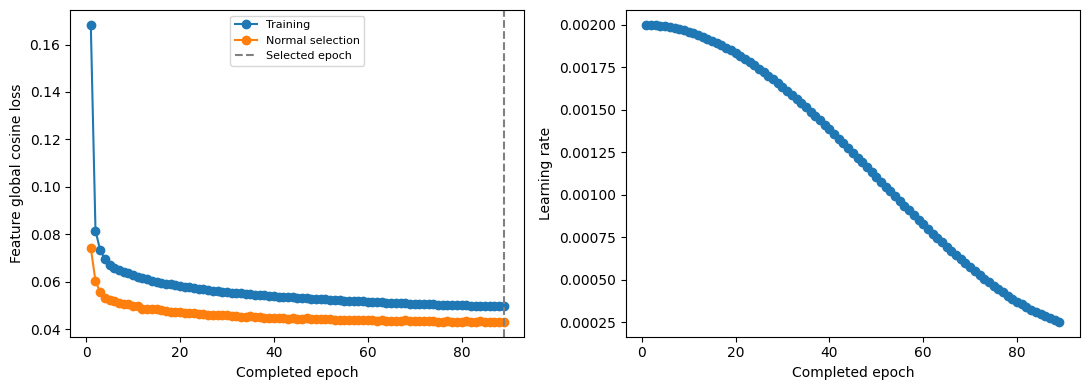

PosixPath('/kaggle/working/Dinomaly100_baseline_8_report.zip')

In [6]:
@torch.inference_mode()
def normal_validation():
    model.eval()
    total, count = 0., 0
    for _, inp in clean_loader('select'):
        check_session_time()
        inp = inp.to(DEVICE, non_blocking=True)
        en, de = model(inp)
        value = global_cosine(en, de)
        if not bool(torch.isfinite(value)):
            raise FloatingPointError('Nonfinite normal-selection feature loss.')
        total += value.item() * len(inp)
        count += len(inp)
    return float(total / count)

def cpu_trainable_state():
    return {k: v.detach().cpu().clone() for k, v in trainable.state_dict().items()}

def optimizer_to_device(optimizer):
    for param, state in optimizer.state.items():
        for key in ('exp_avg', 'exp_avg_sq', 'max_exp_avg_sq'):
            if key in state:
                state[key] = state[key].to(param.device)

def scheduler_clock(scheduler):
    return dict(last_epoch=int(scheduler.last_epoch), _step_count=int(scheduler._step_count),
                _last_lr=[float(v) for v in scheduler.get_last_lr()])

def rng_state():
    return dict(torch_cpu=torch.get_rng_state(),
                torch_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else [])

def restore_rng(state):
    torch.set_rng_state(state['torch_cpu'])
    if DEVICE.type == 'cuda':
        if len(state['torch_cuda']) != torch.cuda.device_count():
            raise RuntimeError('Resume with the same visible GPU count to preserve dropout RNG.')
        torch.cuda.set_rng_state_all(state['torch_cuda'])

def meaningful_normal_improvement(value, anchor):
    if not math.isfinite(anchor):
        return True
    tolerance = max(EARLY_STOPPING_MIN_DELTA,
                    EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT * abs(anchor))
    return value < anchor - tolerance

def resume_bundle():
    destination = RUN.parent / 'Dinomaly100_baseline_8_resume.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_STORED) as z:
        for name in ('config.json', 'last.pt', 'best.pt', 'training_history.csv', 'status.json'):
            path = RUN / name
            if path.is_file():
                z.write(path, name)
    return destination

optimizer = StableAdamW([{'params': trainable.parameters()}], lr=LR, betas=(.9, .999),
                       weight_decay=1e-4, amsgrad=True, eps=1e-8)
scheduler = WarmCosineScheduler(optimizer, base_value=LR, final_value=2e-4,
                              total_iters=TOTAL_STEPS, warmup_iters=100)
for group in optimizer.param_groups:
    group['lr'] = float(group['lr'])
completed, validated_epochs, stale, best_epoch = 0, 0, 0, 0
best_value = stop_anchor = float('inf')
best_weights, history = None, []
epoch_loss_sum, epoch_frames, epoch_seconds = 0., 0, 0.
checkpoint_rng = None
if (RUN / 'last.pt').exists():
    state = load_pt(RUN / 'last.pt')
    if state['config_sha256'] != digest(config):
        raise RuntimeError('Checkpoint/config mismatch; legacy5000-step states cannot be imported.')
    trainable.load_state_dict(state['trainable'], strict=True)
    optimizer.load_state_dict(state['optimizer'])
    optimizer_to_device(optimizer)
    scheduler.load_state_dict({**scheduler.state_dict(), **state['scheduler_clock']})
    completed, validated_epochs = state['step'], state['validated_epochs']
    stale, best_epoch, best_value = state['stale'], state['best_epoch'], state['best_value']
    stop_anchor, best_weights, history = state['stop_anchor'], state['best_weights'], state['history']
    epoch_loss_sum, epoch_frames, epoch_seconds = state['epoch_loss_sum'], state['epoch_frames'], state['epoch_seconds']
    checkpoint_rng = state['rng']
    del state
    if not validated_epochs*STEPS_PER_EPOCH <= completed <= (validated_epochs+1)*STEPS_PER_EPOCH:
        raise RuntimeError('Inconsistent optimizer/epoch position.')
    if not 0 <= validated_epochs <= MAX_EPOCHS or completed > TOTAL_STEPS:
        raise RuntimeError('Saved position exceeds this run budget.')
    print(f'Resume after{completed}updates/{validated_epochs}validated epochs; bestepoch{best_epoch}.')

def commit_training_state():
    save_pt(dict(trainable=cpu_trainable_state(), optimizer=optimizer.state_dict(),
        scheduler_clock=scheduler_clock(scheduler), step=completed,
        validated_epochs=validated_epochs, stale=stale, best_epoch=best_epoch,
        best_value=best_value, stop_anchor=stop_anchor, best_weights=best_weights, history=history,
        epoch_loss_sum=epoch_loss_sum, epoch_frames=epoch_frames, epoch_seconds=epoch_seconds,
        rng=rng_state(), config_sha256=digest(config)), RUN / 'last.pt')
    pd.DataFrame(history).to_csv(RUN / 'training_history.csv', index=False)

def write_training_status(status):
    write_json(RUN / 'status.json', dict(status=status, optimizer_steps=completed,
        completed_epochs=validated_epochs, max_epochs=MAX_EPOCHS,
        best_epoch=best_epoch, stale_epochs=stale, test_evaluated=False))

def train_remaining():
    global completed, validated_epochs, stale, best_epoch, best_value, best_weights, history
    global stop_anchor, epoch_loss_sum, epoch_frames, epoch_seconds
    if checkpoint_rng is not None:
        restore_rng(checkpoint_rng)
    else:
        seed_all(SEED + 50001)
    if not (RUN / 'last.pt').exists():
        commit_training_state()
    progress = tqdm(total=TOTAL_STEPS, initial=completed, desc='Dinomaly optimizer updates')
    try:
        while validated_epochs < MAX_EPOCHS and stale < EARLY_STOPPING_PATIENCE:
            end_step = (validated_epochs + 1) * STEPS_PER_EPOCH
            if completed < end_step:
                sampler = StepBatchSampler(len(train_dataset), BATCH, SEED, completed, end_step)
                loader = DataLoader(train_dataset, batch_sampler=sampler, num_workers=WORKERS,
                    pin_memory=DEVICE.type == 'cuda', persistent_workers=False,
                    generator=torch.Generator().manual_seed(SEED + 912 + validated_epochs))
                model.train()
                model.encoder.eval()
                assert not any(p.requires_grad for p in model.encoder.parameters())
                tick = time.monotonic()
                for _, inp in loader:
                    check_session_time()
                    inp = inp.to(DEVICE, non_blocking=True)
                    p = min(.9 * completed / 1000., .9)
                    optimizer.zero_grad(set_to_none=True)
                    en, de = model(inp)
                    loss = global_cosine_hm_percent(en, de, p=p, factor=.1)
                    if not bool(torch.isfinite(loss)):
                        raise FloatingPointError('Nonfinite source loss; no silent epsilon/precision change.')
                    loss.backward()
                    grad_norm = nn.utils.clip_grad_norm_(trainable.parameters(), max_norm=.1,
                                                        error_if_nonfinite=True)
                    optimizer.step()
                    scheduler.step()
                    for group in optimizer.param_groups:
                        group['lr'] = float(group['lr'])
                    completed += 1
                    epoch_loss_sum += loss.item() * len(inp)
                    epoch_frames += len(inp)
                    progress.update(1)
                    del inp, en, de, loss
                    now = time.monotonic()
                    epoch_seconds += now - tick
                    if completed % SAVE_EVERY == 0 or completed == end_step:
                        commit_training_state()
                        write_training_status('training')
                    tick = time.monotonic()
                del loader
            if completed != end_step or epoch_frames != FRAMES_PER_EPOCH:
                raise RuntimeError('An epoch must include exactly the source drop_last frame budget.')
            tick = time.monotonic()
            selection = normal_validation()
            validation_seconds = time.monotonic() - tick
            improved = meaningful_normal_improvement(selection, stop_anchor)
            validated_epochs += 1
            if selection < best_value:
                best_value, best_epoch = selection, validated_epochs
                best_weights = cpu_trainable_state()
            if improved:
                stop_anchor, stale = selection, 0
            else:
                stale += 1
            history.append(dict(epoch=validated_epochs, optimizer_steps=completed,
                train_global_cosine=epoch_loss_sum/epoch_frames,
                select_global_cosine=selection, frames_this_epoch=epoch_frames,
                training_seconds=epoch_seconds, validation_seconds=validation_seconds,
                lr=float(optimizer.param_groups[0]['lr']), hard_mining_p=min(.9*(completed-1)/1000., .9),
                best_epoch=best_epoch, stale_epochs=stale, stop_anchor=stop_anchor,
                meaningful_improvement=improved))
            print(f'\nEpoch{validated_epochs}/{MAX_EPOCHS}: train={history[-1]["train_global_cosine"]:.6f}, '
                  f'normal={selection:.6f}, bestepoch={best_epoch}, stale={stale}, '
                  f'seconds={epoch_seconds+validation_seconds:.1f}', flush=True)
            mean_seconds = sum(h['training_seconds']+h['validation_seconds'] for h in history)/len(history)
            print(f'Estimated remaining to cap:{mean_seconds*(MAX_EPOCHS-validated_epochs)/3600:.2f}hours; '
                  'normal-only early stopping may finish earlier.', flush=True)
            epoch_loss_sum, epoch_frames, epoch_seconds = 0., 0, 0.
            commit_training_state()
            write_training_status('training')
    except SessionPause as exc:
        # Time checks occur between applied updates or in gradient-free validation.
        # Validation interrupted at an epoch boundary is repeated after resume.
        commit_training_state()
        write_training_status('paused_for_resume')
        print('\n', exc, 'Scientific budget unchanged; no incomplete test evaluation.', flush=True)
    except BaseException:
        # A failed optimizer step is not serialized. Resume last atomic commit.
        report_zip()
        if (RUN / 'last.pt').exists():
            resume_bundle()
        raise
    finally:
        progress.close()

train_remaining()
TRAINING_COMPLETE = validated_epochs >= MAX_EPOCHS or stale >= EARLY_STOPPING_PATIENCE
history_df = pd.DataFrame(history)
if TRAINING_COMPLETE:
    if best_weights is None or best_epoch < 1:
        raise RuntimeError('No normal-selected trained checkpoint.')
    trainable.load_state_dict(best_weights, strict=True)
    best_path = RUN / 'best.pt'
    if not best_path.exists():
        save_pt(dict(model={k:v.detach().cpu() for k,v in model.state_dict().items()},
            epoch=best_epoch, normal_select_loss=best_value, config_sha256=digest(config),
            backbone_sha256=BACKBONE_SHA256), best_path)
    selected = load_pt(best_path)
    if selected['epoch'] != best_epoch or selected['config_sha256'] != digest(config):
        raise RuntimeError('Saved normal-selected checkpoint mismatch.')
    model.load_state_dict(selected['model'], strict=True)
    del selected
    model.eval()
    write_json(RUN / 'selected_checkpoint.json', dict(epoch=best_epoch,
        completed_epochs=validated_epochs, optimizer_steps=completed,
        checkpoint='best.pt', sha256=sha(best_path), normal_selection_loss=best_value,
        selection='lowest observed normal-only global cosine; stopping tolerance separate; no test selection',
        stop_reason='normal_patience' if stale >= EARLY_STOPPING_PATIENCE else 'maximum_epoch_cap',
        stopping_anchor=stop_anchor))
else:
    print('Training paused. Save output and set RESUME_DIR; later cells skip test labels.')
    display(FileLink(str(resume_bundle())))
if len(history_df):
    fig, axes = plt.subplots(1, 2, figsize=(11,4))
    axes[0].plot(history_df.epoch, history_df.train_global_cosine, 'o-', label='Training')
    axes[0].plot(history_df.epoch, history_df.select_global_cosine, 'o-', label='Normal selection')
    axes[0].axvline(best_epoch, color='gray', linestyle='--', label='Selected epoch')
    axes[0].set(xlabel='Completed epoch', ylabel='Feature global cosine loss')
    axes[0].legend(fontsize=8)
    axes[1].plot(history_df.epoch, history_df.lr, 'o-')
    axes[1].set(xlabel='Completed epoch', ylabel='Learning rate')
    fig.tight_layout()
    fig.savefig(RUN / 'training_curve.png', dpi=150)
    plt.show()
report_zip()

## 7. Normal thresholds before test labels

Fit historical all-validation Tukey and calibration-only quantile thresholds. The independently held normal audit measures FPR for quantile rows. Lock selected model and thresholds.

In [7]:
STRUCT = generate_binary_structure(2, 2)

def postprocess(mask):
    m = binary_closing(mask, structure=STRUCT, iterations=2)
    m = binary_opening(m, structure=STRUCT, iterations=1)
    m = binary_fill_holes(m)
    cc, _ = label(m)
    keep = np.bincount(cc.ravel()) >= 50
    keep[0] = False
    return binary_opening(keep[cc], structure=STRUCT, iterations=2)

@torch.inference_mode()
def score_maps(role):
    model.eval()
    s = SCORES[0]
    path = MAP_DIR / f'{s}_{role}.npy'
    shape = (len(splits[role]), SIZE, SIZE)
    if not path.exists():
        temp = path.with_name(path.stem + '.tmp.npy')
        data = np.lib.format.open_memmap(temp, mode='w+', dtype=np.float32, shape=shape)
        begin = time.monotonic()
        for indices, inp in tqdm(clean_loader(role), desc='Score ' + role):
            check_session_time()
            inp = inp.to(DEVICE, non_blocking=True)
            en, de = model(inp)
            result = source_score(en, de).cpu().numpy()
            if not np.isfinite(result).all():
                raise FloatingPointError('Nonfinite score map')
            data[indices.numpy()] = result
        data.flush()
        del data
        temp.replace(path)
        write_json(RUN / f'scoring_runtime_{role}.json', dict(frames=shape[0],
            seconds=time.monotonic() - begin, evaluation_batch=EVAL_BATCH,
            description='end-to-end score generation with loading/transforms; not isolated GPU latency'))
    result = np.load(path, mmap_mode='r')
    assert result.shape == shape and result.dtype == np.float32
    if not all(np.isfinite(frame).all() for frame in result):
        raise FloatingPointError('Nonfinite cached map')
    return {s: result}

def calibrate_scores():
    maps = {role: score_maps(role) for role in ('select', 'calibrate', 'audit')}
    thresholds, audit_rows = {}, []
    for s in SCORES:
        vals = np.concatenate([maps[r][s].ravel() for r in ('select', 'calibrate', 'audit')])
        q1, q3 = np.percentile(vals, [25, 75])
        thresholds[s] = {'historical': float(q3 + 4 * (q3 - q1))}
        del vals
        rng = np.random.default_rng(SEED + 71)
        sample = np.concatenate([a.ravel()[rng.choice(SIZE * SIZE, 4096, replace=False)]
                                 for a in maps['calibrate'][s]])
        for f in FPRS:
            thresholds[s][f'fpr_{f:g}'] = float(np.quantile(sample, 1 - f, method='higher'))
        for protocol, t in thresholds[s].items():
            raw, post = [], []
            for a in maps['audit'][s]:
                pred = a > t
                raw.append(float(pred.mean()))
                post.append(float(postprocess(pred).mean()))
            audit_rows.append(dict(score=s, protocol=protocol, threshold=t,
                audit_raw_fpr=float(np.mean(raw)), audit_post_fpr=float(np.mean(post)),
                audit_used_in_threshold=(protocol == 'historical')))
    write_json(RUN / 'thresholds_LOCKED.json', thresholds)
    audit = pd.DataFrame(audit_rows)
    audit.to_csv(RUN / 'normal_fpr.csv', index=False)
    write_json(RUN / 'evaluation_lock.json', dict(checkpoint_sha256=sha(RUN / 'best.pt'),
        config_sha256=digest(config), thresholds_sha256=sha(RUN / 'thresholds_LOCKED.json'),
        test_masks_decoded=False))
    return maps, thresholds, audit

EVALUATION_READY = False
if TRAINING_COMPLETE:
    MAP_DIR = CACHE / ('scores_' + sha(RUN / 'best.pt')[:16])
    MAP_DIR.mkdir(exist_ok=True)
    try:
        maps, thresholds, audit = calibrate_scores()
        EVALUATION_READY = True
        print('Normal-selected model and thresholds locked. No test mask pixels used yet.')
        display(audit)
    except SessionPause as exc:
        write_json(RUN / 'status.json', dict(status='paused_during_calibration',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed, max_epochs=MAX_EPOCHS, test_evaluated=False,
            reason=str(exc)))
        print(exc, 'Resume with the same config and checkpoints.')
        report_zip()

Score select:   0%|          | 0/131 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Score calibrate:   0%|          | 0/32 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Score audit:   0%|          | 0/59 [00:00<?, ?it/s]

Normal-selected model and thresholds locked. No test mask pixels used yet.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,dinomaly_feature_cosine,historical,0.116022,0.000007,0.000000,True
1,dinomaly_feature_cosine,fpr_0.005,0.077555,0.008153,0.007141,False
2,dinomaly_feature_cosine,fpr_0.01,0.073994,0.014841,0.013359,False
3,dinomaly_feature_cosine,fpr_0.02,0.070028,0.028541,0.026442,False
4,dinomaly_feature_cosine,fpr_0.05,0.064273,0.067747,0.065534,False
5,dinomaly_feature_cosine,fpr_0.1,0.058890,0.130843,0.129712,False


## 8. Shared binary-mask metrics and native map ranking

Evaluate all496test frames after the lock. Report mean foreground IoU per frame, Dice, precision/recall, full pixel AP/AUROC/AUPRO and image ranking when defined. No threshold is chosen using these test labels.

In [8]:
def confusion(pred, target):
    return (int(np.count_nonzero(pred & target)), int(np.count_nonzero(pred & ~target)),
            int(np.count_nonzero(~pred & target)), int(np.count_nonzero(~pred & ~target)))

def iou(tp, fp, fn):
    return tp / (tp + fp + fn) if tp + fp + fn else 1.0

def dice(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0

def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
    # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    for i, m in enumerate(masks):
        cc, n = label(m, structure=STRUCT)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        upper = right
        endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)

def evaluate_test():
    # Check the lock before accessing any test label content.
    lock = json.loads((RUN / 'evaluation_lock.json').read_text())
    assert lock['config_sha256'] == digest(config)
    assert lock['checkpoint_sha256'] == sha(RUN / 'best.pt')
    assert lock['thresholds_sha256'] == sha(RUN / 'thresholds_LOCKED.json')
    maps['test'] = score_maps('test')
    gt = np.lib.format.open_memmap(CACHE / 'test_masks.npy', mode='w+', dtype=np.bool_,
                                 shape=(len(splits['test']), SIZE, SIZE))
    mask_hashes = []
    for i, r in enumerate(tqdm(splits['test'], desc='Decode test masks after lock')):
        with Image.open(r['mask']) as im:
            gt[i] = np.asarray(im.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                               dtype=np.float32) / 255 > .5
        mask_hashes.append(dict(relative=r['relative'], sha256=sha(r['mask'])))
    gt.flush()
    assert gt.any() and not gt.all()
    write_json(RUN / 'mask_hashes.json', mask_hashes)
    rows = []
    for s in SCORES:
        for protocol, t in tqdm(thresholds[s].items(), desc='Masks ' + s):
            for i, r in enumerate(splits['test']):
                raw = maps['test'][s][i] > t
                for processing, pred in [('raw', raw), ('postprocessed', postprocess(raw))]:
                    tp, fp, fn, tn = confusion(pred, gt[i])
                    rows.append(dict(score=s, protocol=protocol, processing=processing,
                                     relative=r['relative'], video=r['video'], tp=tp, fp=fp, fn=fn, tn=tn,
                                     iou=iou(tp, fp, fn), dice=dice(tp, fp, fn),
                                     precision=tp / (tp + fp) if tp + fp else 0.,
                                     recall=tp / (tp + fn) if tp + fn else 0.))
    frames = pd.DataFrame(rows)
    frames.to_csv(RUN / 'test_frame_metrics.csv', index=False)
    keys = ['score', 'protocol', 'processing']
    summaries = []
    for (s, protocol, processing), group in frames.groupby(keys, sort=False):
        tp, fp, fn, tn = [int(group[c].sum()) for c in ('tp', 'fp', 'fn', 'tn')]
        a = audit[(audit.score == s) & (audit.protocol == protocol)].iloc[0]
        summaries.append(dict(
            model=MODEL_LABEL, score=s, protocol=protocol, processing=processing,
            mean_frame_iou=float(group.iou.mean()), mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()), mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()), mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp, fp, fn), pooled_dice=dice(tp, fp, fn),
            pooled_precision=tp / (tp + fp) if tp + fp else 0.,
            pooled_recall=tp / (tp + fn) if tp + fn else 0.,
            audit_raw_fpr=float(a.audit_raw_fpr), audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold), threshold=float(a.threshold),
            n_frames=len(group), total_parameters=PARAMETERS, selected_step=best_epoch*STEPS_PER_EPOCH,
            selected_epoch=best_epoch, completed_epochs=validated_epochs,
            max_epochs=MAX_EPOCHS, optimizer_steps=completed,
            training_image_presentations=completed*BATCH,
            trainable_parameters=TRAINABLE_PARAMETERS, frozen_parameters=FROZEN_PARAMETERS,
        ))
    summary = pd.DataFrame(summaries)
    summary.to_csv(RUN / 'summary.csv', index=False)
    frames.groupby(keys + ['video'], as_index=False).agg(
        mean_frame_iou=('iou', 'mean'), mean_frame_dice=('dice', 'mean'),
        frames=('iou', 'size')).to_csv(RUN / 'test_video_metrics.csv', index=False)
    ranking = []
    for s in SCORES:
        print('Exact full-pixel AP / AUROC / AUPRO:', s, flush=True)
        ranking.append(dict(score=s, **pixel_ranking(maps['test'][s], gt)))
    ranking = pd.DataFrame(ranking)
    ranking.to_csv(RUN / 'full_pixel_ranking.csv', index=False)
    headline = summary[(summary.processing == 'postprocessed') &
                       summary.protocol.isin(['historical', 'fpr_0.02'])].merge(ranking, on='score')
    headline.to_csv(RUN / 'headline_metrics.csv', index=False)
    print('Main historical row: dinomaly_feature_cosine / historical / postprocessed / mean_frame_iou')
    display(headline[['score', 'protocol', 'selected_epoch', 'completed_epochs',
                      'optimizer_steps', 'mean_frame_iou', 'mean_frame_dice', 'pooled_precision',
                      'pooled_recall', 'pixel_ap', 'pixel_auroc', 'pixel_aupro_0p30', 'audit_post_fpr']])
    # Native source image score: mean of the largest1% of pixel scores.
    # Do not mix independent audit frames into the test set just to manufacture negatives.
    from sklearn.metrics import average_precision_score, roc_auc_score
    image_rows, image_ranking = [], []
    for s in SCORES:
        image_scores = []
        for a in maps['test'][s]:
            flat = np.asarray(a).ravel()
            k = max(1, int(len(flat) * .01))
            image_scores.append(float(np.partition(flat, len(flat)-k)[-k:].mean()))
        image_labels = np.asarray([bool(m.any()) for m in gt], dtype=np.int64)
        for i, r in enumerate(splits['test']):
            image_rows.append(dict(score=s, relative=r['relative'], video=r['video'],
                image_score=image_scores[i], mask_has_anomaly=int(image_labels[i])))
        valid = len(np.unique(image_labels)) == 2
        image_ranking.append(dict(score=s, normal_frames=int((image_labels==0).sum()),
            anomalous_frames=int((image_labels==1).sum()),
            image_ap=float(average_precision_score(image_labels, image_scores)) if valid else None,
            image_auroc=float(roc_auc_score(image_labels, image_scores)) if valid else None,
            note='top1% source image score; labels from evaluated masks' if valid else
                 'Undefined discrimination: test split does not contain both image classes.'))
    pd.DataFrame(image_rows).to_csv(RUN / 'test_image_scores.csv', index=False)
    write_json(RUN / 'image_ranking.json', image_ranking)
    return gt, frames, summary, ranking, headline


TEST_EVALUATION_COMPLETE = False
if EVALUATION_READY:
    try:
        gt, frames, summary, ranking, headline = evaluate_test()
        TEST_EVALUATION_COMPLETE = True
    except SessionPause as exc:
        write_json(RUN / 'status.json', dict(status='paused_during_evaluation',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed, max_epochs=MAX_EPOCHS, test_evaluated=False,
            reason=str(exc)))
        print(exc, 'The locked evaluation will finish after resume.')
        report_zip()

Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Score test:   0%|          | 0/124 [00:00<?, ?it/s]

Decode test masks after lock:   0%|          | 0/496 [00:00<?, ?it/s]

Masks dinomaly_feature_cosine:   0%|          | 0/6 [00:00<?, ?it/s]

Exact full-pixel AP / AUROC / AUPRO: dinomaly_feature_cosine
Main historical row: dinomaly_feature_cosine / historical / postprocessed / mean_frame_iou


,score,protocol,selected_epoch,completed_epochs,optimizer_steps,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,pixel_aupro_0p30,audit_post_fpr
0,dinomaly_feature_cosine,historical,89,89,21271,0.000697,0.001352,0.747737,0.000768,0.297238,0.74429,0.297637,0.000000
1,dinomaly_feature_cosine,fpr_0.02,89,89,21271,0.237182,0.372932,0.273332,0.687815,0.297238,0.74429,0.297637,0.026442


## 9. Report and recovery bundle

Retain every fixed result, including weak metrics, and export small reports separately from model weights. The selected epoch and actual optimizer updates are visible.

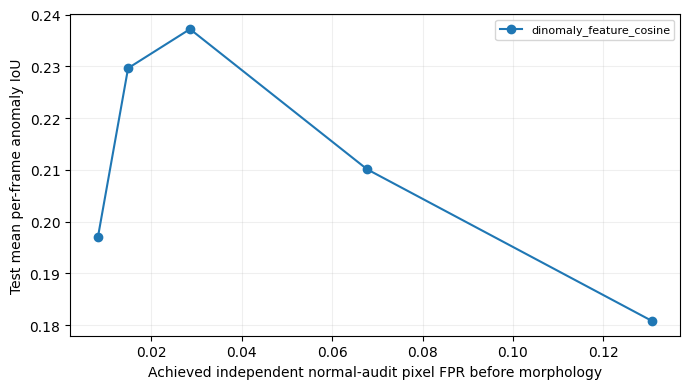

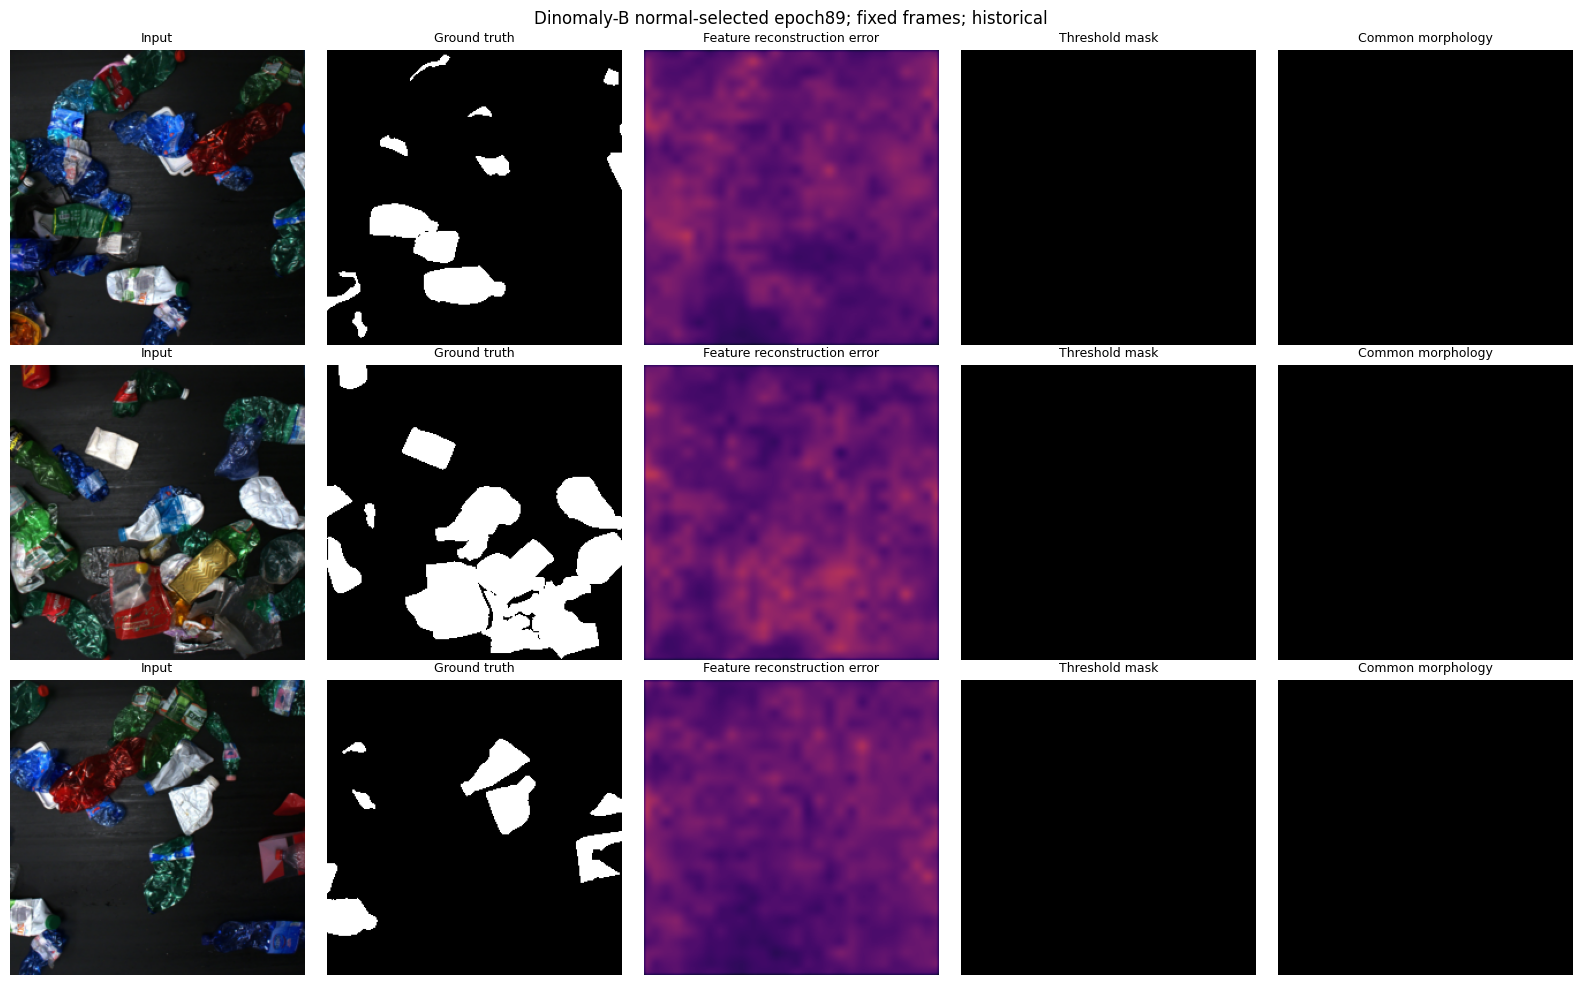

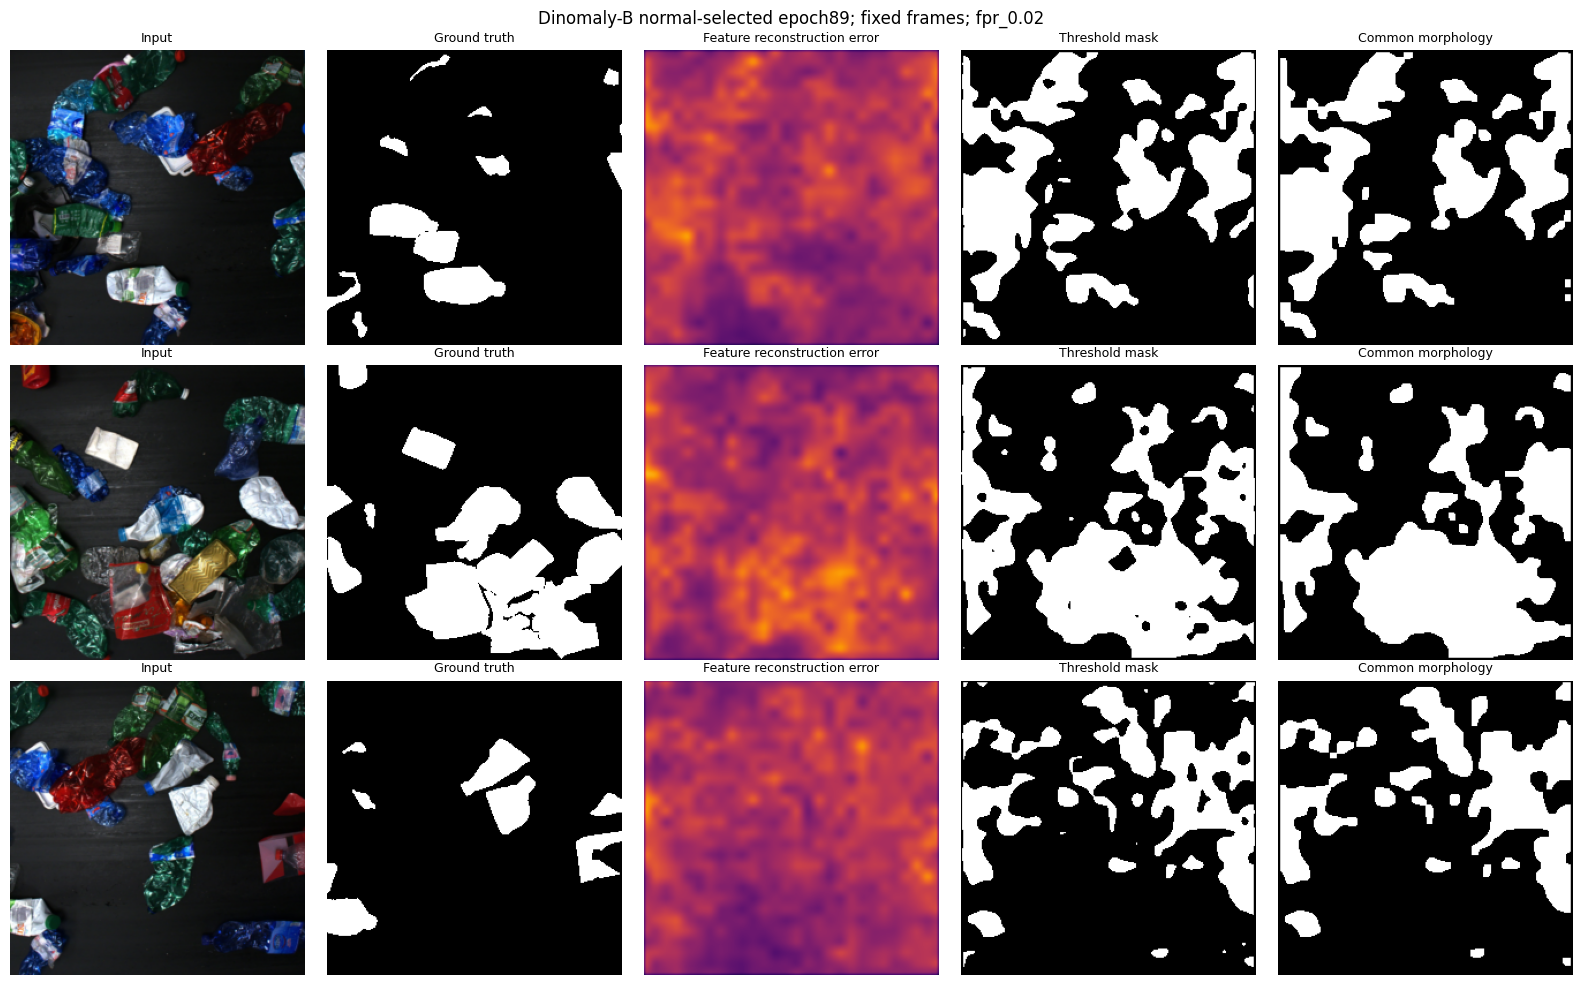

Dinomaly-B original CVPR2025 model; NEW WS2 max100 normal-selected adapter.
Source commit: 1f252be03a918789b19848f0ca37166e7c28dada; model/loss/native score remain pinned.
Completed epochs=89, selected epoch=89, updates=21271.
Maximum100 epochs, patience10, relative anchor improvement0.001, numerical floor1e-8.
Best checkpoint keeps every observed normal-global-cosine minimum, independently of stopping tolerance.
Native paper budget was5000 optimizer steps/fixed-final selection. This run changes the cosine
schedule horizon to100 epochs and checkpoint policy; do not describe it as identical native training.
Actual batch16/source drop_last=True:239 updates and3824 frame presentations per epoch;
13 of3829 normal frames are dropped from each shuffled epoch, not always the same13 frames.
Native warmup100 updates, LR0.002->0.0002, hard-mining ramp1000 updates are retained.
Native5000 checkpoint cannot be resumed into this different schedule; initialize a fresh head.
Total parameters=14800896

/kaggle/working/Dinomaly100_baseline_8_report.zip

/kaggle/working/Dinomaly100_baseline_8_resume.zip

Keep checkpoints in: /kaggle/working/Dinomaly_baseline_8_max100


In [9]:
def final_report():
    fig, ax = plt.subplots(figsize=(7, 4))
    for s in SCORES:
        data = summary[(summary.score == s) & (summary.processing == 'postprocessed') &
                       (summary.protocol != 'historical')].sort_values('audit_raw_fpr')
        ax.plot(data.audit_raw_fpr, data.mean_frame_iou, 'o-', label=s)
    ax.set(xlabel='Achieved independent normal-audit pixel FPR before morphology',
           ylabel='Test mean per-frame anomaly IoU')
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN / 'iou_vs_fpr.png', dpi=150)
    plt.show()
    indices = np.linspace(0, len(splits['test']) - 1, 3, dtype=int)
    data = cache_images('test')
    s = SCORES[0]
    for protocol in ('historical', 'fpr_0.02'):
        fig, axes = plt.subplots(3, 5, figsize=(16, 10))
        t = thresholds[s][protocol]
        for row, idx in enumerate(indices):
            panels = [(data[idx], 'Input', None), (gt[idx], 'Ground truth', 'gray'),
                (maps['test'][s][idx], 'Feature reconstruction error', 'inferno'),
                (maps['test'][s][idx] > t, 'Threshold mask', 'gray'),
                (postprocess(maps['test'][s][idx] > t), 'Common morphology', 'gray')]
            for col, (a, title, cmap) in enumerate(panels):
                axes[row, col].imshow(a, cmap=cmap, vmin=0 if col == 2 else None,
                                      vmax=max(2*t, 1e-8) if col == 2 else None)
                axes[row, col].set_title(title, fontsize=9)
                axes[row, col].axis('off')
        fig.suptitle(f'Dinomaly-B normal-selected epoch{best_epoch}; fixed frames; {protocol}')
        fig.tight_layout()
        fig.savefig(RUN / f'fixed_examples_{protocol}.png', dpi=150)
        plt.show()
    write_json(RUN / 'fixed_examples.json', [splits['test'][int(i)]['relative'] for i in indices])
    status = dict(status='complete', model=MODEL_LABEL, optimizer_steps=completed,
        completed_epochs=validated_epochs, max_epochs=MAX_EPOCHS,
        evaluated_checkpoint='best.pt', selected_epoch=best_epoch,
        selected_step=best_epoch*STEPS_PER_EPOCH, total_parameters=PARAMETERS,
        trainable_parameters=TRAINABLE_PARAMETERS, frozen_parameters=FROZEN_PARAMETERS,
        training_image_presentations=completed*BATCH,
        stop_reason='normal_patience' if stale>=EARLY_STOPPING_PATIENCE else 'maximum_epoch_cap',
        test_evaluated=True,
        cumulative_training_diagnostic_seconds=float(history_df.training_seconds.sum()+history_df.validation_seconds.sum()),
        peak_gpu_allocated_bytes=torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None)
    write_json(RUN / 'status.json', status)
    report_text = f'''Dinomaly-B original CVPR2025 model; NEW WS2 max100 normal-selected adapter.
Source commit: {DINOMALY_COMMIT}; model/loss/native score remain pinned.
Completed epochs={validated_epochs}, selected epoch={best_epoch}, updates={completed}.
Maximum100 epochs, patience10, relative anchor improvement0.001, numerical floor1e-8.
Best checkpoint keeps every observed normal-global-cosine minimum, independently of stopping tolerance.
Native paper budget was5000 optimizer steps/fixed-final selection. This run changes the cosine
schedule horizon to100 epochs and checkpoint policy; do not describe it as identical native training.
Actual batch16/source drop_last=True:239 updates and3824 frame presentations per epoch;
13 of3829 normal frames are dropped from each shuffled epoch, not always the same13 frames.
Native warmup100 updates, LR0.002->0.0002, hard-mining ramp1000 updates are retained.
Native5000 checkpoint cannot be resumed into this different schedule; initialize a fresh head.
Total parameters={PARAMETERS}; trainable={TRAINABLE_PARAMETERS}; frozen={FROZEN_PARAMETERS}.
External official DINOv2 pretraining; FEATURE reconstruction, not RGB and not capacity matched.
Same full-frame256->392 geometry, native cosine score, existing split/masks/thresholds/morphology.
No SAM or real anomaly masks are used in training, stopping, or threshold selection.
Historical mean_frame_iou is mean foreground IoU per frame, identical to mean_iou, not pooled
IoU or background/foreground two-class mIoU. Historical Q3+4IQR uses all normal validation
including audit; quantile thresholds use only calibration and retain an independent audit.
Mean Dice, pooled/frame precision and recall, full-pixel AP/AUROC/AUPRO are included.
Image ranking is undefined if the test split contains only one image class.
Keep all scores including weak results; this is a previously inspected single-seed test set.
Send Dinomaly100_baseline_8_report.zip and executed notebook/log; keep config.json,last.pt,
best.pt and Dinomaly100_baseline_8_resume.zip. Large cached arrays are not needed initially.
'''
    (RUN / 'REPORT.txt').write_text(report_text)
    print(report_text)

if TEST_EVALUATION_COMPLETE:
    final_report()
try:
    (RUN / 'executed_cells.py').write_text('\n\n'.join(get_ipython().history_manager.input_hist_raw))
except (NameError, AttributeError):
    pass
display(FileLink(str(report_zip())))
if (RUN / 'last.pt').exists():
    display(FileLink(str(resume_bundle())))
print('Keep checkpoints in:', RUN)